# Análisis de PideYa · EP2

Este notebook calcula las cifras del informe ejecutivo que no salen directo del dashboard (retención, captación, comunas, pruebas de diferencia) y genera las figuras que usa el informe.

Entrada: las tablas limpias de `data/processed/`, que produce `src/limpieza_pideya.py`. Salida: imágenes en `images/informe/`.

Regla de negocio: ventas, ticket, tiempo y calificación se calculan solo con pedidos entregados.

In [1]:
from pathlib import Path
import math

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

DATA = Path("../data/processed")
IMG = Path("../images")
OUT = IMG / "informe"
OUT.mkdir(exist_ok=True)

usuarios = pd.read_csv(DATA / "usuarios_limpio.csv", parse_dates=["fecha_registro"])
restaurantes = pd.read_csv(DATA / "restaurantes_limpio.csv")
pedidos = pd.read_csv(DATA / "pedidos_limpio.csv", parse_dates=["fecha_pedido"])

df = (pedidos
      .merge(usuarios, on="id_usuario")
      .merge(restaurantes, on="id_restaurante", suffixes=("_usuario", "_restaurante")))
df["mes"] = df["fecha_pedido"].dt.to_period("M")
ent = df[df["estado"] == "Entregado"]

def pct(x, dec=1):
    return f"{x * 100:.{dec}f}%".replace(".", ",")

def num(x, dec=2):
    return f"{x:.{dec}f}".replace(".", ",")

NARANJO, GRIS, OSCURO = "#E4572E", "#9CA3AF", "#1F2937"
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": GRIS, "axes.labelcolor": OSCURO, "xtick.color": OSCURO,
                     "ytick.color": OSCURO})

print(f"Pedidos: {len(df)} | entregados: {len(ent)} | periodo: {df.fecha_pedido.min():%d-%m-%Y} a {df.fecha_pedido.max():%d-%m-%Y}")

Pedidos: 1488 | entregados: 1327 | periodo: 01-05-2026 a 19-10-2026


## 1. Retención: ¿los clientes piden una vez o vuelven?

In [2]:
pedidos_por_cliente = df.groupby("id_usuario").size()
activos = pedidos_por_cliente.size
print(f"Usuarios con al menos un pedido: {activos} de {len(usuarios)}")
print(f"Pidieron una sola vez: {(pedidos_por_cliente == 1).sum()} ({pct((pedidos_por_cliente == 1).mean())})")
print(f"Volvieron a pedir (2 o más): {pct((pedidos_por_cliente >= 2).mean())}")
print(f"3 pedidos o más: {pct((pedidos_por_cliente >= 3).mean())}")
print(f"Mediana de pedidos por cliente: {pedidos_por_cliente.median():.0f} | máximo: {pedidos_por_cliente.max()}")

dias_entre = df.sort_values("fecha_pedido").groupby("id_usuario")["fecha_pedido"].diff().dt.days.dropna()
print(f"Mediana de días entre un pedido y el siguiente: {dias_entre.median():.0f}")

# Retorno de un mes al siguiente. Se omite sep -> oct porque octubre llega solo hasta el día 19.
meses = sorted(df["mes"].unique())
clientes_mes = {m: set(df.loc[df["mes"] == m, "id_usuario"]) for m in meses}
for a, b in zip(meses[:-2], meses[1:-1]):
    vuelven = len(clientes_mes[a] & clientes_mes[b])
    print(f"{a} -> {b}: {vuelven} de {len(clientes_mes[a])} vuelven ({pct(vuelven / len(clientes_mes[a]))})")

ultimo = df.groupby("id_usuario")["fecha_pedido"].max()
corte = df["fecha_pedido"].max()
inactivos = (ultimo < corte - pd.Timedelta(days=45)).sum()
print(f"Clientes sin pedidos en los últimos 45 días: {inactivos} ({pct(inactivos / activos)})")

# ¿Una cancelación espanta al cliente? Comparamos según cómo terminó su primer pedido.
primero = df.sort_values("fecha_pedido").groupby("id_usuario").first()
for estado in ["Entregado", "Cancelado"]:
    ids = primero.index[primero["estado"] == estado]
    print(f"Primer pedido {estado.lower()}: {num(pedidos_por_cliente.loc[ids].mean())} pedidos en promedio")

Usuarios con al menos un pedido: 298 de 300
Pidieron una sola vez: 7 (2,3%)
Volvieron a pedir (2 o más): 97,7%
3 pedidos o más: 88,6%
Mediana de pedidos por cliente: 5 | máximo: 12
Mediana de días entre un pedido y el siguiente: 19
2026-05 -> 2026-06: 107 de 189 vuelven (56,6%)
2026-06 -> 2026-07: 96 de 165 vuelven (58,2%)
2026-07 -> 2026-08: 99 de 184 vuelven (53,8%)
2026-08 -> 2026-09: 96 de 163 vuelven (58,9%)
Clientes sin pedidos en los últimos 45 días: 73 (24,5%)
Primer pedido entregado: 5,00 pedidos en promedio
Primer pedido cancelado: 4,94 pedidos en promedio


## 2. Captación de usuarios nuevos

In [3]:
registros = usuarios.groupby(usuarios["fecha_registro"].dt.to_period("M")).size()
r2026 = registros[registros.index >= pd.Period("2026-01")]
print(r2026.to_string())
print(f"Promedio ene a may 2026: {num(r2026[:'2026-05'].mean(), 1)} por mes")
print(f"Promedio jun a sep 2026: {num(r2026['2026-06':'2026-09'].mean(), 1)} por mes")
print(f"Registros en octubre 2026: {registros.get(pd.Period('2026-10'), 0)}")
print(f"Último registro en la tabla: {usuarios['fecha_registro'].max():%d-%m-%Y}")

fecha_registro
2026-01    13
2026-02    10
2026-03    15
2026-04    16
2026-05    15
2026-06    11
2026-07     8
2026-08     6
2026-09    10
Freq: M
Promedio ene a may 2026: 13,8 por mes
Promedio jun a sep 2026: 8,8 por mes
Registros en octubre 2026: 0
Último registro en la tabla: 29-09-2026


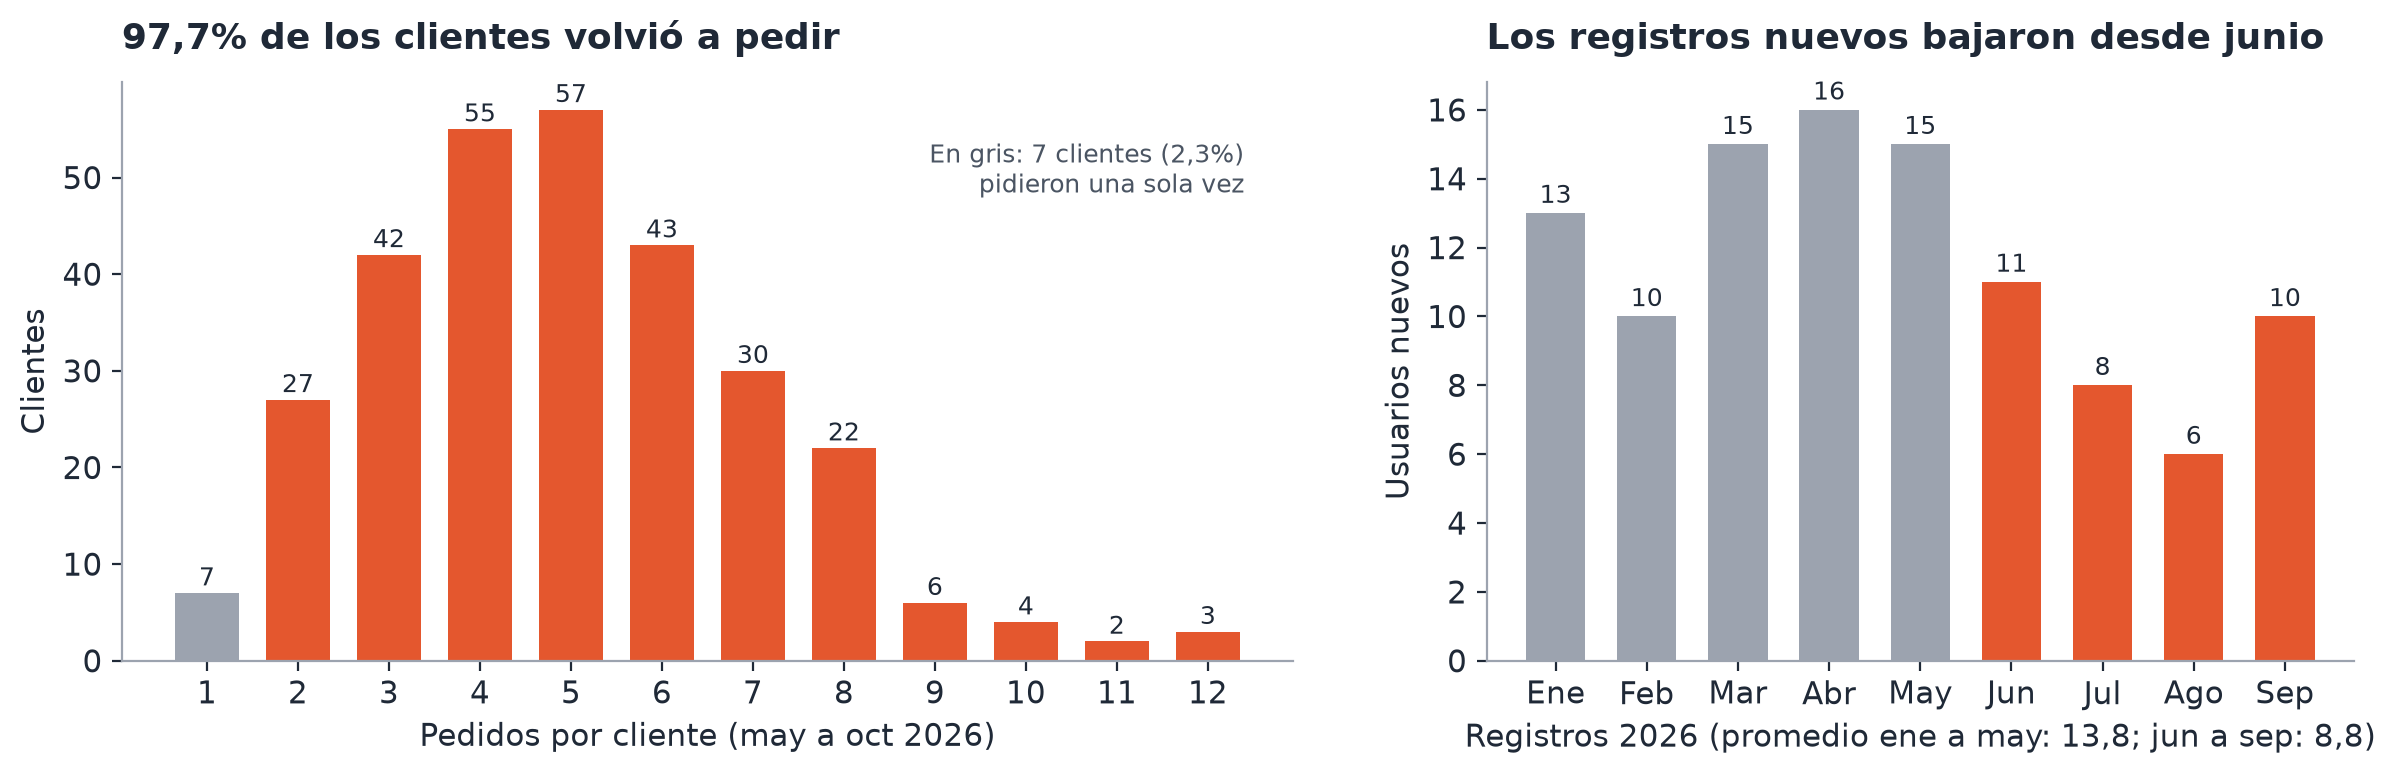

In [4]:
# Figura del informe: retención (izquierda) y captación 2026 (derecha)
dist = pedidos_por_cliente.value_counts().sort_index()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), dpi=200, gridspec_kw={"width_ratios": [1.35, 1]})

ax1.bar(dist.index, dist.values, color=[GRIS if n == 1 else NARANJO for n in dist.index], width=0.7)
for x, y in zip(dist.index, dist.values):
    ax1.text(x, y + 0.8, str(y), ha="center", fontsize=9, color=OSCURO)
ax1.set_xticks(dist.index)
ax1.set_xlabel("Pedidos por cliente (may a oct 2026)")
ax1.set_ylabel("Clientes")
ax1.set_title(f"{pct((pedidos_por_cliente >= 2).mean())} de los clientes volvió a pedir", loc="left",
              fontsize=13, fontweight="bold", color=OSCURO, pad=12)
ax1.text(12.4, dist.max() * 0.85, f"En gris: {dist.loc[1]} clientes ({pct(dist.loc[1] / activos)})\npidieron una sola vez",
         ha="right", fontsize=9, color="#4B5563")

meses_es = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep"]
colores = [GRIS] * 5 + [NARANJO] * 4
ax2.bar(meses_es, r2026.values, color=colores, width=0.65)
for i, v in enumerate(r2026.values):
    ax2.text(i, v + 0.3, str(v), ha="center", fontsize=9, color=OSCURO)
ax2.set_ylabel("Usuarios nuevos")
ax2.set_xlabel(f"Registros 2026 (promedio ene a may: {num(r2026[:'2026-05'].mean(), 1)}; jun a sep: {num(r2026['2026-06':'2026-09'].mean(), 1)})")
ax2.set_title("Los registros nuevos bajaron desde junio", loc="left", fontsize=13, fontweight="bold",
              color=OSCURO, pad=12)
fig.tight_layout(w_pad=3)
fig.savefig(OUT / "fig_retencion.png")
plt.show()

## 3. Comunas: ¿dónde hay espacio para crecer?

La comuna del usuario describe la demanda; la del restaurante, la oferta. Solo una parte de los pedidos se hace a un restaurante de la misma comuna, así que se miran por separado.

In [5]:
misma = (df["comuna_usuario"] == df["comuna_restaurante"]).mean()
print(f"Pedidos a un restaurante de la misma comuna del usuario: {pct(misma)}")

c = pd.DataFrame({
    "usuarios": usuarios.groupby("comuna").size(),
    "restaurantes": restaurantes[restaurantes["comuna"] != "Sin información"].groupby("comuna").size(),
    "pedidos": df.groupby("comuna_usuario").size(),
    "ventas": ent.groupby("comuna_usuario")["monto_clp"].sum(),
    "cancelacion_usuario": df.groupby("comuna_usuario")["estado"].apply(lambda s: (s == "Cancelado").mean()),
    "cancelacion_restaurante": df.groupby("comuna_restaurante")["estado"].apply(lambda s: (s == "Cancelado").mean()),
    "satisfechos": ent.groupby("comuna_usuario")["calificacion"].apply(lambda s: (s >= 4).sum() / s.count()),
    "pct_premium": usuarios.groupby("comuna")["tipo_cuenta"].apply(lambda s: (s == "Premium").mean()),
    "nuevos_desde_mayo": usuarios[usuarios["fecha_registro"] >= "2026-05-01"].groupby("comuna").size(),
}).drop(index="Sin información", errors="ignore")
c["pedidos_por_usuario"] = c["pedidos"] / c["usuarios"]
c["pct_ventas"] = c["ventas"] / c["ventas"].sum()
c.sort_values("ventas", ascending=False).round(3)

Pedidos a un restaurante de la misma comuna del usuario: 18,7%


,usuarios,restaurantes,pedidos,ventas,cancelacion_usuario,cancelacion_restaurante,satisfechos,pct_premium,nuevos_desde_mayo,pedidos_por_usuario,pct_ventas
Santiago,96.0,9.0,467.0,4634300.0,0.116,0.084,0.765,0.219,18.0,4.865,0.313
La Florida,44.0,4.0,231.0,2289600.0,0.104,0.118,0.830,0.409,8.0,5.250,0.155
Providencia,46.0,3.0,213.0,2152500.0,0.113,0.073,0.794,0.370,6.0,4.630,0.145
Ñuñoa,41.0,6.0,211.0,2151300.0,0.081,0.128,0.796,0.220,7.0,5.146,0.145
Las Condes,43.0,3.0,220.0,2143700.0,0.118,0.138,0.801,0.279,2.0,5.116,0.145
Maipú,30.0,2.0,146.0,1438300.0,0.110,0.173,0.808,0.200,9.0,4.867,0.097


## 4. Restaurantes y categorías

In [6]:
r = (df.groupby(["nombre_restaurante", "categoria", "comuna_restaurante"])
       .agg(pedidos=("id_pedido", "size"), cancelados=("estado", lambda s: (s == "Cancelado").sum()))
       .join(ent.groupby(["nombre_restaurante", "categoria", "comuna_restaurante"])
             .agg(ventas=("monto_clp", "sum"), calificacion=("calificacion", "mean"),
                  n_calificaciones=("calificacion", "count"),
                  notas_bajas=("calificacion", lambda s: (s <= 3).sum() / s.count()))))
r["cancelacion"] = r["cancelados"] / r["pedidos"]
print("Más pedidos:")
print(r.sort_values("pedidos", ascending=False).head(3)[["pedidos", "ventas"]].to_string())
print("\nMejor calificación:")
print(r.sort_values("calificacion", ascending=False).head(3)[["calificacion", "n_calificaciones"]].round(2).to_string())
print("\nCalificación bajo 4,0:")
print(r[r["calificacion"] < 4].sort_values("calificacion")[["ventas", "calificacion", "notas_bajas"]].round(3).to_string())
print("\nMayor cancelación:")
print(r.sort_values("cancelacion", ascending=False).head(5)[["pedidos", "cancelados", "cancelacion"]].round(3).to_string())

Más pedidos:
                                                 pedidos  ventas
nombre_restaurante categoria comuna_restaurante                 
Panadería del Sol  Italiana  Ñuñoa                    68  759100
Café Central       Saludable La Florida               63  606000
La Baguette        Italiana  Santiago                 62  711600

Mejor calificación:
                                                 calificacion  n_calificaciones
nombre_restaurante categoria comuna_restaurante                                
Mar y Tierra       Saludable Ñuñoa                       4.44                27
Tacos y Punto      Saludable Providencia                 4.41                44
Ramen Ya           Asiática  Maipú                       4.28                50

Calificación bajo 4,0:
                                                     ventas  calificacion  notas_bajas
nombre_restaurante categoria     comuna_restaurante                                   
Dulce Tentación    Italiana      Providenci

In [7]:
cat = (df.groupby("categoria")
         .agg(restaurantes=("id_restaurante", "nunique"), pedidos=("id_pedido", "size"),
              cancelacion=("estado", lambda s: (s == "Cancelado").mean()))
         .join(ent.groupby("categoria").agg(ventas=("monto_clp", "sum"), calificacion=("calificacion", "mean"),
                                            satisfechos=("calificacion", lambda s: (s >= 4).sum() / s.count()))))
cat["pct_ventas"] = cat["ventas"] / cat["ventas"].sum()
cat.sort_values("ventas", ascending=False).round(3)

,restaurantes,pedidos,cancelacion,ventas,calificacion,satisfechos,pct_ventas
categoria,,,,,,,
Saludable,11,532,0.115,5152900,4.219,0.826,0.348
Asiática,8,382,0.136,3948600,4.123,0.782,0.267
Italiana,5,285,0.084,3280800,4.089,0.757,0.222
Comida rápida,5,241,0.083,2151200,4.083,0.790,0.145
Postres y café,1,48,0.083,276200,4.071,0.762,0.019


## 5. Cancelación: ¿qué diferencias son reales?

Prueba z de dos proporciones. Un valor p bajo (menor a 0,05) indica que la diferencia difícilmente se debe al azar.

In [8]:
def prueba_proporciones(x1, n1, x2, n2):
    p1, p2 = x1 / n1, x2 / n2
    p = (x1 + x2) / (n1 + n2)
    z = (p1 - p2) / math.sqrt(p * (1 - p) * (1 / n1 + 1 / n2))
    return p1, p2, math.erfc(abs(z) / math.sqrt(2))

cancel = df["estado"] == "Cancelado"
total_c, total_n = cancel.sum(), len(df)

def contra_resto(mascara, nombre):
    x1, n1 = cancel[mascara].sum(), mascara.sum()
    p1, p2, p = prueba_proporciones(x1, n1, total_c - x1, total_n - n1)
    print(f"{nombre}: {pct(p1)} vs {pct(p2)} el resto | p = {num(p, 3)}")

contra_resto(df["comuna_restaurante"] == "Maipú", "Restaurantes de Maipú")
contra_resto(df["categoria"] == "Asiática", "Categoría Asiática")
contra_resto(df["mes"] == pd.Period("2026-08"), "Agosto")

prem, est = df["tipo_cuenta"] == "Premium", df["tipo_cuenta"] == "Estándar"
p1, p2, p = prueba_proporciones(cancel[prem].sum(), prem.sum(), cancel[est].sum(), est.sum())
print(f"Premium vs Estándar: {pct(p1)} vs {pct(p2)} | p = {num(p)}")

print("\nRestaurantes de Maipú:", ", ".join(restaurantes.loc[restaurantes.comuna == "Maipú", "nombre_restaurante"] + " (" + restaurantes.loc[restaurantes.comuna == "Maipú", "categoria"] + ")"))

Restaurantes de Maipú: 17,3% vs 10,3% el resto | p = 0,027
Categoría Asiática: 13,6% vs 9,9% el resto | p = 0,042
Agosto: 7,0% vs 11,6% el resto | p = 0,036
Premium vs Estándar: 12,4% vs 10,8% | p = 0,39

Restaurantes de Maipú: Trattoria Roma (Asiática), Ramen Ya (Asiática)


In [9]:
# Cuánto bajaría la tasa total si los 5 locales con más cancelación llegaran a la meta de 8 %.
top5 = r.sort_values("cancelacion", ascending=False).head(5)
cancelaciones_top5 = top5["cancelados"].sum()
pedidos_top5 = top5["pedidos"].sum()
nueva_tasa = (total_c - cancelaciones_top5 + 0.08 * pedidos_top5) / total_n
print(f"Los 5 locales suman {cancelaciones_top5} de {total_c} cancelaciones ({pct(cancelaciones_top5 / total_c)}) con {pct(pedidos_top5 / total_n)} de los pedidos")
print(f"Tasa total si esos 5 cancelaran al 8 %: {pct(nueva_tasa)} (hoy {pct(total_c / total_n)})")

Los 5 locales suman 42 de 161 cancelaciones (26,1%) con 15,5% de los pedidos
Tasa total si esos 5 cancelaran al 8 %: 9,2% (hoy 10,8%)


In [10]:
# Calificación de Dulce Tentación contra el resto (prueba t de Welch, aproximación normal)
dt = ent.loc[ent["nombre_restaurante"] == "Dulce Tentación", "calificacion"].dropna()
resto = ent.loc[ent["nombre_restaurante"] != "Dulce Tentación", "calificacion"].dropna()
t = (dt.mean() - resto.mean()) / math.sqrt(dt.var() / len(dt) + resto.var() / len(resto))
print(f"Dulce Tentación: {num(dt.mean())} ({len(dt)} notas) vs resto {num(resto.mean())} | p = {num(math.erfc(abs(t) / math.sqrt(2)), 3)}")

Dulce Tentación: 3,77 (47 notas) vs resto 4,16 | p = 0,006


## 6. Entrega y medios de pago

In [11]:
t = ent["tiempo_entrega_min"].dropna()
print(f"Tiempo promedio: {num(t.mean(), 1)} min | mediana: {t.median():.0f} min | a tiempo (<= 30 min): {pct((t <= 30).mean())}")
print(f"Correlación tiempo y calificación: {num(abs(ent[['tiempo_entrega_min', 'calificacion']].corr().iloc[0, 1]))}")

pago = (df.groupby("metodo_pago")
          .agg(pedidos=("id_pedido", "size"), cancelacion=("estado", lambda s: (s == "Cancelado").mean()))
          .join(ent.groupby("metodo_pago").agg(ticket=("monto_clp", "mean"), calificacion=("calificacion", "mean"))))
pago["participacion"] = pago["pedidos"] / pago["pedidos"].sum()
pago.round(3)

Tiempo promedio: 31,5 min | mediana: 32 min | a tiempo (<= 30 min): 45,0%
Correlación tiempo y calificación: 0,00


,pedidos,cancelacion,ticket,calificacion,participacion
metodo_pago,,,,,
Efectivo,380,0.111,11169.231,4.087,0.255
Tarjeta,864,0.111,11203.125,4.175,0.581
Transferencia,244,0.094,10997.738,4.114,0.164


                    mean  count
tiempo_entrega_min             
20 o menos          4.19    125
21 a 30             4.12    415
31 a 40             4.13    473
41 a 50             4.22    165
Más de 50           4.16     19


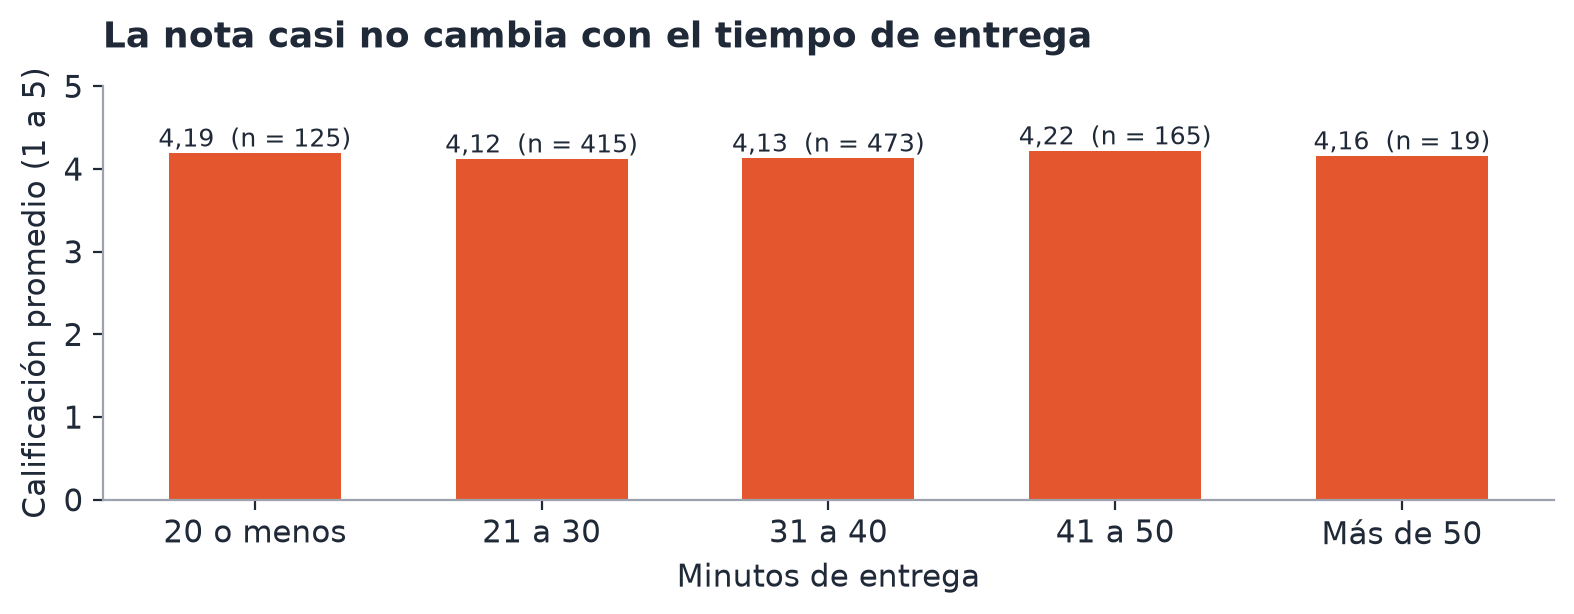

In [12]:
rangos = pd.cut(ent["tiempo_entrega_min"], bins=[0, 20, 30, 40, 50, 999],
                labels=["20 o menos", "21 a 30", "31 a 40", "41 a 50", "Más de 50"])
por_rango = ent.groupby(rangos, observed=True)["calificacion"].agg(["mean", "count"])
print(por_rango.round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 3.2), dpi=200)
ax.bar(por_rango.index.astype(str), por_rango["mean"], color=NARANJO, width=0.6)
for i, (m, n) in enumerate(zip(por_rango["mean"], por_rango["count"])):
    ax.text(i, m + 0.08, f"{num(m)}  (n = {n})", ha="center", fontsize=9, color=OSCURO)
ax.set_ylim(0, 5)
ax.set_ylabel("Calificación promedio (1 a 5)")
ax.set_xlabel("Minutos de entrega")
ax.set_title("La nota casi no cambia con el tiempo de entrega", loc="left", fontsize=13,
             fontweight="bold", color=OSCURO, pad=14)
fig.tight_layout()
fig.savefig(OUT / "fig_tiempo_calificacion.png")
plt.show()

## 7. Premium contra Estándar

In [13]:
clientes = pd.DataFrame({"pedidos": pedidos_por_cliente,
                         "meses_activos": df.groupby("id_usuario")["mes"].nunique()}).join(usuarios.set_index("id_usuario"))
comp = (clientes.groupby("tipo_cuenta").agg(clientes=("pedidos", "size"), pedidos_por_cliente=("pedidos", "mean"),
                                            meses_activos=("meses_activos", "mean"))
        .join(ent.groupby("tipo_cuenta").agg(ticket=("monto_clp", "mean"), calificacion=("calificacion", "mean")))
        .join(df.groupby("tipo_cuenta")["estado"].apply(lambda s: (s == "Cancelado").mean()).rename("cancelacion")))
comp.round(3)

,clientes,pedidos_por_cliente,meses_activos,ticket,calificacion,cancelacion
tipo_cuenta,,,,,,
Estándar,200,4.980,3.350,11173.086,4.166,0.108
Premium,83,4.940,3.349,11081.058,4.097,0.124
Sin información,15,5.467,3.467,11373.750,4.081,0.024


## 8. Recortes del dashboard para el informe

Cada hallazgo del informe se apoya en un gráfico del dashboard. Estos recortes salen de las capturas en `images/`.

In [14]:
recortes = {
    "fig_cancelacion.png": ("dashboard_2_operacion.png", (180, 210, 961, 601)),
    "fig_dispersion_restaurantes.png": ("dashboard_2_operacion.png", (970, 210, 1313, 601)),
    "fig_ventas_categoria.png": ("dashboard_1_resumen.png", (667, 210, 1008, 739)),
}
for salida, (origen, caja) in recortes.items():
    Image.open(IMG / origen).crop(caja).save(OUT / salida)
    print(f"{salida}: {caja[2] - caja[0]} x {caja[3] - caja[1]} px")

fig_cancelacion.png: 781 x 391 px
fig_dispersion_restaurantes.png: 343 x 391 px
fig_ventas_categoria.png: 341 x 529 px
